# Expected Threat: fitting and action valuation

**Analytical question:** Value locations and completed movement.

**Stages in this notebook:** Action counts; reward; transition matrix; iterative solution; endpoint gain.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## xT as a Markov reward model, from scratch
For each state, count shots, goals and attempted movements. Estimate `p_shot`, scoring conditional on shooting, and successful transition probability per **all state actions**. Failed moves contribute zero continuation in this formulation. Iterate `V = immediate_goal_reward + successful_transition @ V`. The function accepts an action table and trains the grid; the demonstration uses clearly synthetic actions because the supplied dynamic-event schema is not a complete verified shot/move training corpus. [Karun Singh](https://karun.in/blog/expected-threat.html).

#### Helper: `fit_xt`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [4]:
def fit_xt(actions,n_states,tolerance=1e-10,max_iter=10000):
    totals=np.bincount(actions.start,minlength=n_states).astype(float)
    reward=np.zeros(n_states);transitions=np.zeros((n_states,n_states))
    for a in actions.itertuples():
        if a.kind=='shot':reward[a.start]+=float(a.goal)
        elif a.success:transitions[a.start,int(a.end)]+=1
    denominator=np.maximum(totals,1)
    reward/=denominator;transitions/=denominator[:,None]
    V=np.zeros(n_states)
    for _ in range(max_iter):
        next_V=reward+transitions@V
        if np.max(np.abs(next_V-V))<tolerance:return next_V,transitions,reward
        V=next_V
    raise ValueError('xT did not converge; inspect recurrent states and termination')

In [5]:
toy_actions=pd.DataFrame([dict(start=0,end=1,kind='move',success=True,goal=False),dict(start=0,end=1,kind='move',success=False,goal=False),dict(start=1,end=1,kind='shot',success=False,goal=True),dict(start=1,end=1,kind='shot',success=False,goal=False)])
V,T,reward=fit_xt(toy_actions,2)
assert np.allclose(V,[.25,.5])
print('Synthetic fitted values:',V)

Synthetic fitted values: [0.25 0.5 ]


### Intermediate steps: Follow the xT value updates

Synthetic two-state training example: the goal-adjacent state learns its reward first, then the upstream state inherits value through successful transitions.

Run the helper functions, inspect their returned arrays/tables, then compare the panels in calculation order.

#### Helper: `xt_iterations`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [6]:
def xt_iterations(transition,reward,steps=8):
    value=np.zeros(len(reward));history=[value.copy()]
    for _ in range(steps):
        continuation=transition@value
        value=reward+continuation;history.append(value.copy())
    return np.array(history)

,to state 0,to state 1
from state 0,0.0,0.5
from state 1,0.0,0.0


,state 0 value,state 1 value
iteration,,
0,0.00,0.0
1,0.00,0.5
2,0.25,0.5
3,0.25,0.5
4,0.25,0.5
5,0.25,0.5
6,0.25,0.5
7,0.25,0.5
8,0.25,0.5


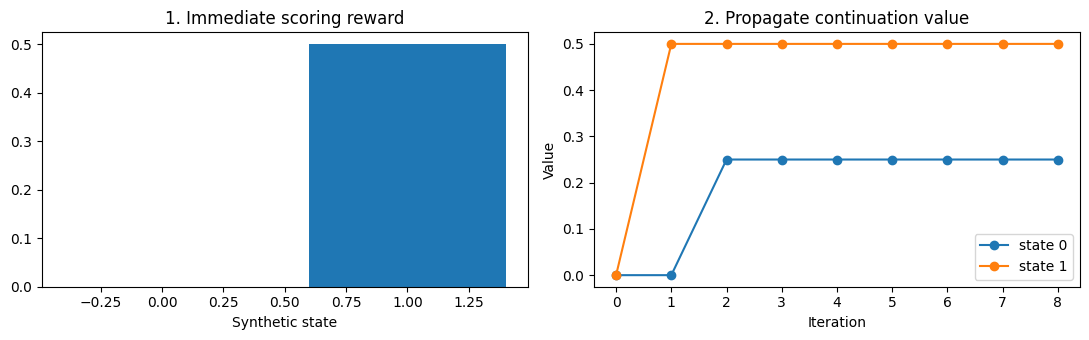

In [7]:
history=xt_iterations(T,reward)
display(pd.DataFrame(T,columns=['to state 0','to state 1'],index=['from state 0','from state 1']))
display(pd.DataFrame(history,columns=['state 0 value','state 1 value']).rename_axis('iteration'))
fig,axs=plt.subplots(1,2,figsize=(11,3.5))
axs[0].bar(range(len(reward)),reward)
axs[0].set(title='1. Immediate scoring reward',xlabel='Synthetic state')
axs[1].plot(history,'o-')
axs[1].set(title='2. Propagate continuation value',xlabel='Iteration',ylabel='Value')
axs[1].legend(['state 0','state 1'])
plt.tight_layout()
plt.show()

#### Helper: `endpoint_gain`
Read the function inputs and returned objects, then run the invocation cells that follow.

In [8]:
def endpoint_gain(values,start,end):return np.asarray(values)[end]-np.asarray(values)[start]

,start_state,end_state,start_value,end_value,gain
0,0,1,0.01,0.03,0.02
1,1,2,0.03,0.12,0.09
2,2,0,0.12,0.01,-0.11


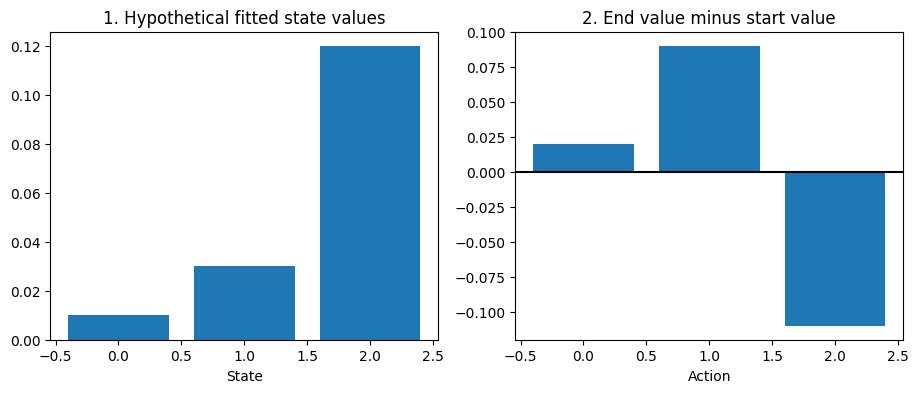

In [9]:
values=np.array([.01,.03,.12])
starts=np.array([0,1,2])
ends=np.array([1,2,0])
gain=endpoint_gain(values,starts,ends)
display(pd.DataFrame({'start_state':starts,'end_state':ends,'start_value':values[starts],'end_value':values[ends],'gain':gain}))
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].bar(range(3),values)
axs[0].set(title='1. Hypothetical fitted state values',xlabel='State')
axs[1].bar(range(3),gain)
axs[1].axhline(0,c='black')
axs[1].set(title='2. End value minus start value',xlabel='Action')
plt.show()

## Review the full method
Trace each final quantity back through its helper functions, intermediate arrays and visual diagnostics. Change one modeling assumption and rerun its dependent cells. Review coverage, attack direction, phase context and evaluation design before interpreting real sample results. Keep synthetic demonstrations and proxy quantities separate from trained or production model outputs.

This notebook is deliberately self-contained. Shared *concepts* such as smoothing or graph normalization are repeated inline where needed; another notebook never needs to run first.
